# 03 · Riesgo por calle con descenso del gradiente (Hugo)

El dataset dice cuántas denuncias hubo por **distrito**, no por calle. La idea (Risk Terrain Modeling, Caplan et al., 2011) es que el delito se concentra cerca de ciertos lugares que sí están en OSM.

1. Para cada tramo de calle se cuentan los lugares cercanos.
2. El riesgo de un tramo es una suma ponderada de esos factores.
3. Los pesos se ajustan con **descenso del gradiente programado por nosotros**, para que la suma del riesgo de las calles de cada distrito se parezca a sus denuncias (43 distritos).
4. El riesgo se normaliza de 0 a 1 y se eligen los puntos críticos de los distritos piloto.

Entradas: `data/osm/` (por defecto, datos reales) y `data/processed/lima_robo_hurto_mensual.csv`.
Salidas: `data/processed/riesgo_calles.csv`, `data/processed/puntos_criticos.csv` y figuras en `outputs/figuras/`.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.optimize import nnls

os.environ.setdefault("PATRULLA_OSM", "local")
sys.path.insert(0, "../src")
import fuente_osm as fuente

PROCESADOS = fuente.RAIZ / "data" / "processed"
FIGURAS = fuente.RAIZ / "outputs" / "figuras"
CRS = fuente.CRS_METROS

# Parámetros del modelo
RADIO_M = 100                  # lugares a menos de 100 m del tramo
ALCANCE_POLICIA_M = 1000       # la cercanía a la policía baja de 1 a 0 entre 0 y 1 km
POLICIA = "toda"               # "toda" (amenity=police) o "solo_comisarias" (nombre con "comisar")
USAR_ALUMBRADO = False         # se quitó: muy pocos tramos tienen la etiqueta lit (ver sección 1)
PILOTOS = ["150101", "150132"] # Cercado de Lima y San Juan de Lurigancho
SEPARACION_M = 300
MAX_PUNTOS, MIN_PUNTOS = 8, 5

print("Fuente:", fuente.fuente())
assert not fuente.es_mock(), "Con datos simulados se sobrescribirían los resultados reales de data/processed/"

Fuente: local


## 1. Cargar calles y lugares
Se usa la red **sin dirección**: cada tramo de calle aparece una sola vez, aunque sea de doble sentido.

In [2]:
limites = fuente.cargar_limites()
lugares = fuente.cargar_lugares(limites).to_crs(CRS)
G = fuente.cargar_calles()
Gu = fuente.ox.convert.to_undirected(G)
tramos = fuente.ox.graph_to_gdfs(Gu, nodes=False).to_crs(CRS)
tramos = tramos[["length", "geometry"] + (["lit"] if "lit" in tramos else [])]
print(f"Tramos: {len(tramos):,} | Lugares: {len(lugares):,}".replace(",", " "))

# Cada tramo pertenece al distrito donde cae su punto medio
medio = gpd.GeoDataFrame(geometry=tramos.geometry.interpolate(0.5, normalized=True), crs=CRS)
lim_m = limites.to_crs(CRS)
asignado = gpd.sjoin_nearest(medio, lim_m[["UBIGEO", "geometry"]], how="left")
tramos["UBIGEO"] = asignado.loc[~asignado.index.duplicated(), "UBIGEO"].values
assert tramos["UBIGEO"].notna().all() and tramos["UBIGEO"].nunique() == 43

Tramos: 204 112 | Lugares: 4 921


In [3]:
# ¿Alcanza la etiqueta lit para usar el alumbrado como factor?
con_lit = tramos.groupby("UBIGEO")["lit"].apply(lambda s: s.notna().mean()) if "lit" in tramos else pd.Series(0.0, index=limites.UBIGEO)
print("Tramos con etiqueta lit en toda Lima:", f"{tramos['lit'].notna().mean():.1%}" if "lit" in tramos else "0%")
print(con_lit.loc[PILOTOS].map("{:.1%}".format).to_string())

Tramos con etiqueta lit en toda Lima: 1.9%
UBIGEO
150101    4.6%
150132    3.2%


## 2. Factores de cada tramo
* `bares`, `paraderos`, `mercados`, `bancos_cajeros`: lugares a menos de 100 m del tramo.
* `cerca_policia`: 1 si hay una comisaría pegada al tramo y baja en línea recta hasta 0 a 1 km.
* `base`: vale 1 en todos los tramos. Su peso es el riesgo que tiene cualquier calle solo por existir; sin él, un distrito con muchas calles y pocos lugares quedaría con riesgo 0.

In [4]:
CATEGORIAS = {"bar": "bares", "paradero": "paraderos", "mercado": "mercados", "banco_cajero": "bancos_cajeros"}

for categoria, columna in CATEGORIAS.items():
    puntos = lugares[lugares["CATEGORIA"] == categoria]
    _, idx_tramo = tramos.sindex.query(puntos.geometry, predicate="dwithin", distance=RADIO_M)
    tramos[columna] = np.bincount(idx_tramo, minlength=len(tramos))

policia = lugares[lugares["CATEGORIA"] == "comisaria"]
if POLICIA == "solo_comisarias":
    nombres = gpd.read_file(fuente.carpeta() / "lugares.geojson").to_crs(CRS)
    nombres = nombres[nombres["amenity"] == "police"]
    policia = nombres[nombres["name"].fillna("").str.contains("comisar", case=False)]
cercano = gpd.sjoin_nearest(medio, policia[["geometry"]], distance_col="d")
d = cercano.loc[~cercano.index.duplicated(), "d"].values
tramos["cerca_policia"] = np.clip(1 - d / ALCANCE_POLICIA_M, 0, 1)
tramos["base"] = 1
if USAR_ALUMBRADO:
    tramos["sin_alumbrado"] = (tramos["lit"] == "no").astype(int)

FACTORES = ["base", "bares", "paraderos", "mercados", "bancos_cajeros"] + (["sin_alumbrado"] if USAR_ALUMBRADO else []) + ["cerca_policia"]
SIGNO = np.array([1] * (len(FACTORES) - 1) + [-1])  # la policía resta riesgo
print("Policía usada:", POLICIA, len(policia))
tramos[FACTORES].describe().round(2)

Policía usada: toda 296


,base,bares,paraderos,mercados,bancos_cajeros,cerca_policia
count,204112.0,204112.00,204112.00,204112.00,204112.00,204112.00
mean,1.0,0.02,0.19,0.07,0.09,0.21
std,0.0,0.30,0.66,0.30,0.51,0.28
min,1.0,0.00,0.00,0.00,0.00,0.00
25%,1.0,0.00,0.00,0.00,0.00,0.00
50%,1.0,0.00,0.00,0.00,0.00,0.00
75%,1.0,0.00,0.00,0.00,0.00,0.43
max,1.0,17.00,21.00,7.00,18.00,1.00


## 3. Objetivo por distrito
Promedio de denuncias mensuales de robo y hurto de cada distrito, **solo con los meses de entrenamiento (2018–2024)**, igual que la división temporal del proyecto.

In [5]:
datos = pd.read_csv(PROCESADOS / "lima_robo_hurto_mensual.csv", dtype={"UBIGEO": str})
objetivo = datos[datos["CONJUNTO"] == "entrenamiento"].groupby("UBIGEO")["TOTAL"].mean()

# Una fila por distrito: suma de cada factor sobre sus tramos (con el signo de la fórmula)
X_dist = tramos.groupby("UBIGEO")[FACTORES].sum().loc[objetivo.index] * SIGNO
y = objetivo.values.astype(float)
X = X_dist.values.astype(float)
X_dist.assign(DENUNCIAS_MES=y.round(1)).head()

,base,bares,paraderos,mercados,bancos_cajeros,cerca_policia,DENUNCIAS_MES
UBIGEO,,,,,,,
150101,4014,276,1544,601,1133,-1996.919222,935.1
150102,5205,25,525,143,21,-532.894752,41.9
150103,13988,71,692,597,860,-1533.882673,415.5
150104,642,414,229,46,164,-256.739815,95.5
150105,777,20,85,164,204,-468.487956,152.8


## 4. Descenso del gradiente programado por nosotros
Modelo: denuncias del distrito ≈ Σ wⱼ · (suma del factor j en el distrito).
Pérdida: error cuadrático medio. Los pesos se mantienen **mayores o iguales a 0** (descenso del gradiente proyectado), así cada factor solo puede actuar en el sentido de la fórmula: los lugares suman y la policía resta.
Los factores y el objetivo se escalan dividiendo por su máximo para que el gradiente no lo domine el factor con números más grandes. El paso se fija en 1/L, con L la constante de Lipschitz del gradiente, lo que garantiza que la pérdida baje en cada iteración.

In [6]:
def descenso_gradiente(X, y, iteraciones=20000):
    escala_x, escala_y = np.abs(X).max(axis=0), y.max()
    Xs, ys = X / escala_x, y / escala_y
    n = len(ys)
    L = 2 / n * np.linalg.eigvalsh(Xs.T @ Xs).max()
    w = np.zeros(Xs.shape[1])
    perdidas = []
    for _ in range(iteraciones):
        error = Xs @ w - ys
        perdidas.append(np.mean(error ** 2))
        gradiente = 2 / n * Xs.T @ error
        w = np.maximum(w - gradiente / L, 0)   # paso + proyección a w >= 0
    return w * escala_y / escala_x, np.array(perdidas)

w, perdidas = descenso_gradiente(X, y)
w_nnls, _ = nnls(X, y)  # solución exacta de referencia, solo para comprobar
pesos = pd.DataFrame({"factor": FACTORES, "peso": w, "peso_referencia": w_nnls, "signo": SIGNO})
print("Diferencia máxima con la solución exacta (relativa):", np.max(np.abs(X @ w - X @ w_nnls)) / y.max())
pesos

Diferencia máxima con la solución exacta (relativa): 5.470862464515705e-16


,factor,peso,peso_referencia,signo
0,base,0.001458,0.001458,1
1,bares,0.000000,0.000000,1
2,paraderos,0.044922,0.044922,1
3,mercados,0.176959,0.176959,1
4,bancos_cajeros,0.240281,0.240281,1
5,cerca_policia,0.000000,0.000000,-1


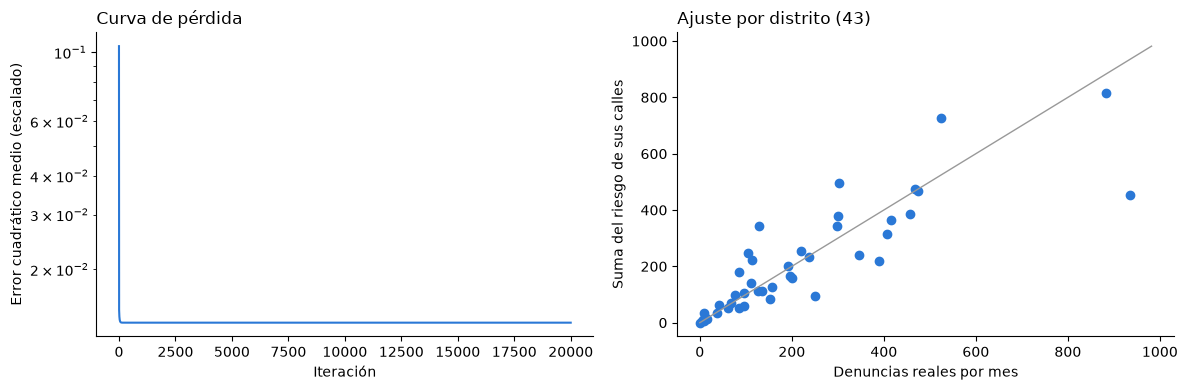

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(perdidas, color="#2a78d6")
ejes[0].set_yscale("log"); ejes[0].set_xlabel("Iteración"); ejes[0].set_ylabel("Error cuadrático medio (escalado)")
ejes[0].set_title("Curva de pérdida", loc="left")
pred = X @ w
ejes[1].scatter(y, pred, color="#2a78d6")
lim_ = [0, max(y.max(), pred.max()) * 1.05]
ejes[1].plot(lim_, lim_, color="#999", linewidth=1)
ejes[1].set_xlabel("Denuncias reales por mes"); ejes[1].set_ylabel("Suma del riesgo de sus calles")
ejes[1].set_title("Ajuste por distrito (43)", loc="left")
for a in ejes: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIGURAS / "riesgo_ajuste.png", dpi=150); plt.show()

## 5. ¿Los lugares aportan algo más que el tamaño del distrito?
Validación dejando un distrito fuera: se ajusta con 42 y se predice el que quedó fuera, 43 veces.
Se compara contra un **modelo base que solo usa la cantidad de tramos** (distritos con más calles, más denuncias). Si el modelo completo no le gana, los lugares de OSM no están explicando el delito.

In [8]:
def dejar_uno_fuera(X, y):
    pred = np.zeros_like(y)
    for i in range(len(y)):
        fuera = np.arange(len(y)) != i
        w_i, _ = descenso_gradiente(X[fuera], y[fuera], iteraciones=5000)
        pred[i] = X[i] @ w_i
    return pred

def metricas(real, pred):
    return {"MAE": np.mean(np.abs(real - pred)), "MAPE %": np.mean(np.abs(real - pred) / real) * 100,
            "R2": 1 - np.sum((real - pred) ** 2) / np.sum((real - real.mean()) ** 2)}

completo = dejar_uno_fuera(X, y)
solo_tramos = dejar_uno_fuera(X[:, [0]], y)
comparacion = pd.DataFrame({"Solo cantidad de tramos": metricas(y, solo_tramos),
                            "Modelo completo": metricas(y, completo)}).T.round(2)
comparacion

,MAE,MAPE %,R2
Solo cantidad de tramos,132.11,159.79,0.19
Modelo completo,76.54,45.87,0.63


## 6. Riesgo de cada tramo, de 0 a 1
riesgo = Σ wⱼ · signoⱼ · factorⱼ. Se recorta al percentil 99 antes de normalizar para que unos pocos tramos extremos (por ejemplo, rodeados de cajeros) no aplasten al resto. **Todos los valores quedan en [0, 1]**, que es lo que necesita la heurística de A*.

In [9]:
crudo = (tramos[FACTORES].values * SIGNO) @ w
tope = np.percentile(crudo, 99)
piso = crudo.min()
tramos["RIESGO"] = (np.clip(crudo, piso, tope) - piso) / (tope - piso)
tramos["RIESGO_CRUDO"] = crudo  # sin recortar: sirve para ordenar los puntos críticos
assert tramos["RIESGO"].between(0, 1).all()
print(f"Tramos recortados en 1: {(crudo >= tope).sum()}")

salida = tramos.reset_index()[["u", "v", "key", "UBIGEO", "length"] + FACTORES + ["RIESGO_CRUDO", "RIESGO"]]
salida.to_csv(PROCESADOS / "riesgo_calles.csv", index=False)
print("Guardado riesgo_calles.csv", salida.shape)
tramos.groupby("UBIGEO")["RIESGO"].mean().sort_values(ascending=False).head(10).rename("riesgo medio")

Tramos recortados en 1: 2205


Guardado riesgo_calles.csv (204112, 13)


UBIGEO
150116    0.194918
150131    0.189048
150122    0.186330
150113    0.159179
150105    0.140189
150141    0.138844
150101    0.135410
150120    0.133029
150130    0.124863
150115    0.122431
Name: riesgo medio, dtype: float64

## 7. Puntos críticos de los distritos piloto
El riesgo de una esquina es el promedio del riesgo **sin recortar** de los tramos que llegan a ella (con el valor recortado, cientos de esquinas empatarían en 1). Se toma la esquina más riesgosa, luego la siguiente que esté a más de 300 m de las ya elegidas, y así hasta tener 8 (mínimo 5). Sin k-means.

In [10]:
nodos = fuente.ox.graph_to_gdfs(Gu, edges=False).to_crs(CRS)
r = tramos.reset_index()[["u", "v", "RIESGO_CRUDO", "UBIGEO"]]
riesgo_nodo = pd.concat([r[["u", "RIESGO_CRUDO"]].rename(columns={"u": "nodo"}),
                         r[["v", "RIESGO_CRUDO"]].rename(columns={"v": "nodo"})]).groupby("nodo")["RIESGO_CRUDO"].mean()
nodos["RIESGO"] = riesgo_nodo.reindex(nodos.index).fillna(0)

filas = []
for u in PILOTOS:
    poligono = lim_m.loc[lim_m["UBIGEO"] == u, "geometry"].iloc[0]
    candidatos = nodos[nodos.within(poligono)].sort_values("RIESGO", ascending=False)
    elegidos = []
    for osmid, fila in candidatos.iterrows():
        if all(fila.geometry.distance(e.geometry) >= SEPARACION_M for _, e in elegidos):
            elegidos.append((osmid, fila))
        if len(elegidos) == MAX_PUNTOS:
            break
    assert len(elegidos) >= MIN_PUNTOS, f"{u}: solo {len(elegidos)} puntos"
    latlon = gpd.GeoSeries([e.geometry for _, e in elegidos], crs=CRS).to_crs("EPSG:4326")
    for orden, ((osmid, e), p) in enumerate(zip(elegidos, latlon), 1):
        filas.append({"UBIGEO": u, "ORDEN": orden, "NODO": osmid, "LAT": p.y, "LON": p.x, "RIESGO_CRUDO": round(e["RIESGO"], 2), "RIESGO": round(float(np.clip((e["RIESGO"] - piso) / (tope - piso), 0, 1)), 4)})

puntos = pd.DataFrame(filas)
puntos.to_csv(PROCESADOS / "puntos_criticos.csv", index=False)
puntos

,UBIGEO,ORDEN,NODO,LAT,LON,RIESGO_CRUDO,RIESGO
0,150101,1,263119251,-12.079226,-77.032126,1.70,1.0
1,150101,2,2832790205,-12.043489,-77.042203,1.62,1.0
2,150101,3,4403514919,-12.048214,-77.034307,1.38,1.0
3,150101,4,2832784188,-12.040484,-77.043272,1.28,1.0
4,150101,5,9333228549,-12.057763,-77.038011,1.20,1.0
5,150101,6,1354143324,-12.057315,-77.026000,1.14,1.0
6,150101,7,888357854,-12.049491,-77.038045,1.10,1.0
7,150101,8,885797762,-12.050962,-77.025751,1.10,1.0
8,150132,1,1975409837,-11.968437,-77.004657,1.12,1.0
9,150132,2,817385731,-12.007789,-77.004547,1.05,1.0


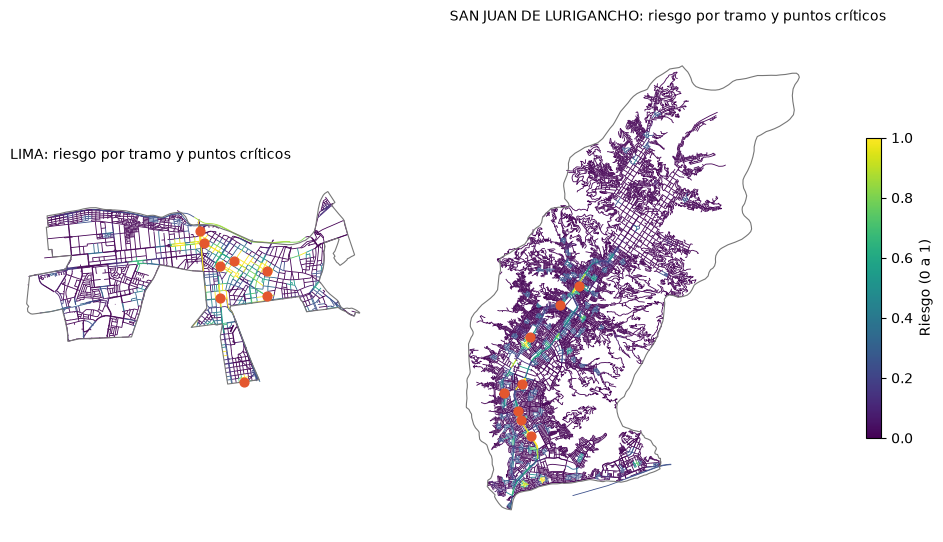

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 6.5))
for eje, u in zip(ejes, PILOTOS):
    t = tramos[tramos["UBIGEO"] == u]
    t.sort_values("RIESGO").plot(ax=eje, column="RIESGO", cmap="viridis", linewidth=0.6, vmin=0, vmax=1)
    p = nodos.loc[puntos.loc[puntos["UBIGEO"] == u, "NODO"]]
    p.plot(ax=eje, color="#e4572e", markersize=40, zorder=3)
    lim_m[lim_m["UBIGEO"] == u].boundary.plot(ax=eje, color="#777", linewidth=0.8)
    eje.set_title(f"{limites.set_index('UBIGEO').loc[u, 'DIST_NORM']}: riesgo por tramo y puntos críticos", loc="left", fontsize=10)
    eje.set_axis_off()
plt.colorbar(ejes[1].collections[0], ax=ejes, shrink=0.6, label="Riesgo (0 a 1)")
plt.savefig(FIGURAS / "riesgo_pilotos.png", dpi=150, bbox_inches="tight"); plt.show()

## 8. Limitaciones (para Evaluación y ética)
* Se calibra con solo 43 distritos: los pesos son orientativos, no causales.
* OSM no tiene todos los lugares (por ejemplo, muy pocos bares) y casi no tiene alumbrado.
* Las denuncias dependen de dónde la gente denuncia, no solo de dónde ocurre el delito.
* Un riesgo alto marca una calle para patrullar, no a las personas que viven o pasan por ahí.